# Plotting

In [3]:
%load_ext autoreload 
%autoreload 2
# reload modules imported 
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from lib.latex_plots import configure_matplotlib
configure_matplotlib()


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
DATA = Path('../data')
FIGS = Path('../plots/adri')
FIGS.mkdir(exist_ok=True)
EXTERNAL = DATA/'external'
PROCESSED = DATA/'processed'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Cargar ----------
works  = pd.read_parquet(EXTERNAL/'works.parquet')
papers = pd.read_parquet(EXTERNAL/'papers_cleaned.gencat.parquet')
hosts  = pd.read_parquet(EXTERNAL/'host_orgs.parquet')

# ---------- 2. Normalizar DOI ----------
def norm_doi(s):
    return (s.astype(str).str.strip().str.lower()
            .str.replace(r'^https?://(dx\.)?doi\.org/', '', regex=True))

works['doi_key']  = norm_doi(works['doi'])
papers['doi_key'] = norm_doi(papers['doi'])

# 1 fila por DOI (evita duplicados preprint/publicado)
papers = papers.dropna(subset=['doi_key']).drop_duplicates('doi_key')
works  = works.drop_duplicates('doi_key')

# ---------- 3. Merge papers ↔ works ----------
df = papers[['doi_key', 'date']].merge(works, on='doi_key', how='inner')

# ---------- 4. Año ----------
df['year'] = pd.to_datetime(df['date'], errors='coerce').dt.year
df = df.dropna(subset=['year'])
df['year'] = df['year'].astype(int)

# ---------- 5. Join con hosts (nombre del publisher) ----------
# Columna en `works` que contiene el openalex_id del publisher
dup = hosts['openalex_id'].duplicated().sum()
if dup:
    print(f'⚠️ {dup} openalex_id duplicados en host_orgs '
          f'(paper con >1 host org). Me quedo con el primero.')

hosts_small = (hosts[['openalex_id', 'host_organization_name']]

               .drop_duplicates('openalex_id', keep='first'))

df = df.merge(hosts_small, on='openalex_id', how='left')


# ---------- 6. Campo APC ----------
APC_COL = 'apc_list_value_usd'   # o 'apc_list_value_usd'
df[APC_COL] = pd.to_numeric(df[APC_COL], errors='coerce').fillna(0)

# ---------- 7. Clasificar editoriales ----------
name = df['host_organization_name'].fillna('').str.lower()
df['group'] = np.select(
    [name.str.contains('elsevier',  na=False),
     name.str.contains('springer',  na=False),
     name.str.contains('oxford',    na=False),
     name.str.contains('wiley',     na=False)],
    ['Elsevier', 'Springer', 'Oxford', 'Wiley'],
    default='Others',
)

# ---------- 8. Agregar por año ----------
order = ['Elsevier', 'Springer', 'Oxford', 'Wiley', 'Others']
pivot_anual = (df.groupby(['year', 'group'])[APC_COL]
           .sum()
           .unstack(fill_value=0)
           .reindex(columns=order, fill_value=0)
           .sort_index())
pivot = pivot_anual.cumsum()
pivot.round(0)

group,Elsevier,Springer,Oxford,Wiley,Others
year,,,,,
1949,0.0,0.0,3750.0,0.0,0.0
1952,0.0,0.0,8670.0,0.0,0.0
1953,3800.0,0.0,8670.0,0.0,0.0
1954,3800.0,4390.0,8670.0,0.0,3000.0
1956,7600.0,4390.0,8670.0,0.0,3000.0
...,...,...,...,...,...
2022,267476592.0,94494574.0,37299256.0,103624987.0,208110723.0
2023,284649383.0,101299171.0,39802893.0,110554683.0,228786008.0
2024,302207431.0,107974783.0,42482883.0,117548207.0,247894709.0


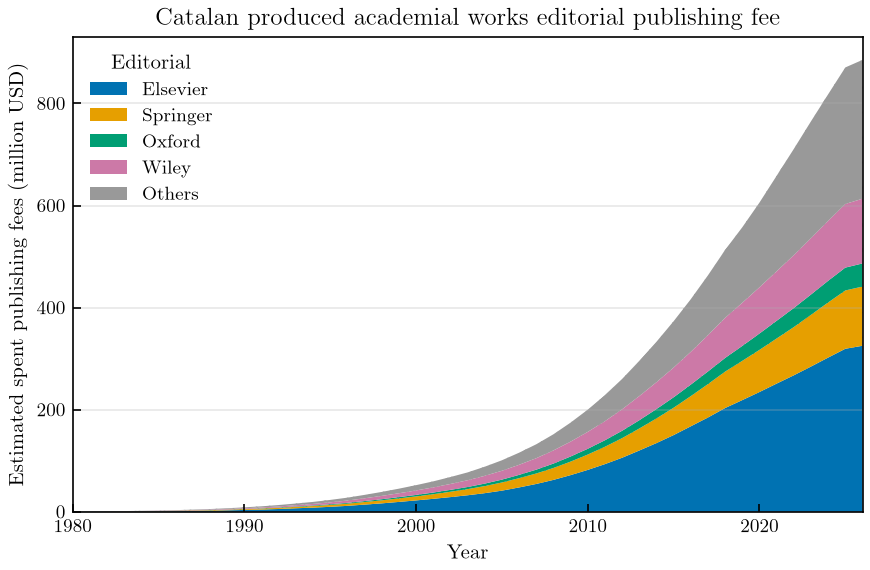

In [7]:
import matplotlib.ticker as mtick

pivot_anual = pd.read_parquet(PROCESSED/'spent_money_per_year_of_publishers.parquet')
pivot = pivot_anual.cumsum()
order = ['Elsevier', 'Springer', 'Oxford', 'Wiley', 'Others']

# CVD-safe palette
COLORS = {
    'Elsevier': '#0072B2',
    'Springer': '#E69F00',
    'Oxford':   '#009E73',
    'Wiley':    '#CC79A7',
    'Others':   '#999999',
}
colors = [COLORS[g] for g in order]

# Secondary encoding (redundant with color, CVD-friendly)
HATCHES = ['', '//', '\\\\', '..', 'xx']   # '\\\\' = 2 backslashes en el string

# Scale by millions
# pivot_m = pivot / 1e6

# Thin hatch strokes (por defecto 1.0)
plt.rcParams['hatch.linewidth'] = 0.5

# ---------- 9. Stacked area plot (millones USD) ----------
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
pivot.plot(kind='area', stacked=True, ax=ax,
             color=colors, linewidth=0)

# Hatch + edgecolor contrastado (imprescindible para que se vea)
for pc, h in zip(ax.collections, HATCHES):
    pc.set_hatch(h)
    pc.set_edgecolor('white')   # color de la raya
    pc.set_linewidth(0)         # sin contorno de polígono

ax.set_xlabel('Year')
ax.set_xlim(1980, 2026)
ax.set_ylabel('Estimated spent publishing fees (million USD)')
ax.set_title('Catalan produced academial works editorial publishing fee')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:,.0f}'))
ax.legend(title='Editorial', loc='upper left', frameon=False)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS/'apc_stacked_by_year.pdf', bbox_inches='tight')
plt.show()